## Milestone 2 — RNN Experiment

We use an LSTM (Long Short-Term Memory) to predict image quality (MOS) by processing each image as a sequence of pixel rows.

The LSTM uses hidden and cell states, controlled by gates, to retain relevant information across the sequence. A GRU (Gated Recurrent Unit) follows a similar principle but uses a simpler architecture with fewer gates and no separate cell state.

We chose the LSTM to experiment with its memory mechanism for image quality prediction.

In [1]:
# %pip install nbformat
%run ./TP2_Base.ipynb

import torch.nn as nn
import torch.optim as optim

PyTorch: 2.13.0+cu130
Device: cuda
Dataset size: 10073
Image shape: torch.Size([3, 128, 128])
MOS label: 3.83
Training samples: 8058
Validation samples: 1007
Test samples: 1008
Dimensions des images : torch.Size([32, 3, 128, 128])
Dimensions des labels : torch.Size([32])
Les 5 premiers MOS : tensor([3.6881, 3.6566, 3.0917, 3.5050, 2.2477])


### Architecture

#### Image-to-Sequence Transformation

Each 128×128 RGB image is converted into a sequence of **128 rows**, each containing **128 × 3 = 384 values**.

- `permute()` reorders the dimensions to `(batch, height, width, channels)`.
- `reshape()` flattens each row to obtain `(batch, 128, 384)`.

This transformation is performed directly in the model's `forward()` method, for each batch during training and prediction.

#### LSTM Regressor

We use a single-layer LSTM with 128 hidden units to process the sequence of pixel rows.

The final hidden state summarizes information from the sequence and is passed through a linear layer to predict a single MOS value per image.

In [2]:
import torch.nn as nn

class LSTMRegressor(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=384,
            hidden_size=128,
            num_layers=1,
            batch_first=True
        )
        self.fc = nn.Linear(128, 1)

    def forward(self, x):
        # Convert images into sequences of rows
        x = x.permute(0, 2, 3, 1).reshape(x.size(0), x.size(2), -1)

        _, (h_n, _) = self.lstm(x)

        # Predict MOS from the last hidden state
        return self.fc(h_n[-1]).squeeze(-1)


In [3]:


torch.manual_seed(42)
model = LSTMRegressor().to(device)


images, labels = next(iter(train_loader))
images = images.to(device)

predictions = model(images)

print("Predictions shape:", predictions.shape)
print("First predictions:", predictions[:5].detach().cpu())


Predictions shape: torch.Size([32])
First predictions: tensor([-0.0119, -0.0055, -0.0164,  0.0980,  0.0262])


### Training

#### Configuration

We use **MSELoss** to measure the squared difference between predicted and actual MOS values, and the **Adam optimizer** to update the model's weights.

The learning rate is set to `0.001`.

In [4]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

#### Training and Validation

We train the LSTM for **20 epochs**, evaluating its performance on the validation set after each epoch.

We use **checkpointing** to save the model weights whenever the validation MSE improves, allowing us to restore the best-performing model after training.

In [5]:


from pathlib import Path

import torch

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)
best_model_path = models_dir / "lstm_best.pth"

rnn_train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)


num_epochs = 20
train_losses = []
val_losses = []

best_val_loss = float("inf")
best_epoch = 0

for epoch in range(num_epochs):
    model.train()
    total_train_loss = 0

    for images, labels in rnn_train_loader:
        images, labels = images.to(device), labels.to(device)

        predictions = model(images)
        loss = criterion(predictions, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * images.size(0)

    train_loss = total_train_loss / len(rnn_train_loader.dataset)
    
    # Validation
    model.eval()
    total_val_loss = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            predictions = model(images)
            loss = criterion(predictions, labels)

            total_val_loss += loss.item() * images.size(0)

    val_loss = total_val_loss / len(val_loader.dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Save the best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        torch.save(model.state_dict(), best_model_path)

    print(f"Epoch {epoch+1}/{num_epochs} | Train MSE: {train_loss:.4f} | Val MSE: {val_loss:.4f}")

# Load the best model weights
model.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)


print(f"\nBest epoch: {best_epoch}")
print(f"Best Validation MSE: {best_val_loss:.4f}")

Epoch 1/20 | Train MSE: 0.5444 | Val MSE: 0.2823
Epoch 2/20 | Train MSE: 0.2579 | Val MSE: 0.2700
Epoch 3/20 | Train MSE: 0.2474 | Val MSE: 0.2569
Epoch 4/20 | Train MSE: 0.2395 | Val MSE: 0.2597
Epoch 5/20 | Train MSE: 0.2383 | Val MSE: 0.2825
Epoch 6/20 | Train MSE: 0.2387 | Val MSE: 0.2570
Epoch 7/20 | Train MSE: 0.2353 | Val MSE: 0.2590
Epoch 8/20 | Train MSE: 0.2282 | Val MSE: 0.2749
Epoch 9/20 | Train MSE: 0.2234 | Val MSE: 0.2850
Epoch 10/20 | Train MSE: 0.2293 | Val MSE: 0.2651
Epoch 11/20 | Train MSE: 0.2182 | Val MSE: 0.2615
Epoch 12/20 | Train MSE: 0.2117 | Val MSE: 0.2663
Epoch 13/20 | Train MSE: 0.2082 | Val MSE: 0.2554
Epoch 14/20 | Train MSE: 0.2043 | Val MSE: 0.2600
Epoch 15/20 | Train MSE: 0.2041 | Val MSE: 0.2660
Epoch 16/20 | Train MSE: 0.2000 | Val MSE: 0.2531
Epoch 17/20 | Train MSE: 0.1944 | Val MSE: 0.2562
Epoch 18/20 | Train MSE: 0.1911 | Val MSE: 0.2638
Epoch 19/20 | Train MSE: 0.1894 | Val MSE: 0.2612
Epoch 20/20 | Train MSE: 0.1840 | Val MSE: 0.2639

Best epo

### Evaluation and Analysis

#### Learning Curves

We plot the training and validation MSE across epochs to analyze convergence, generalization, and potential overfitting.

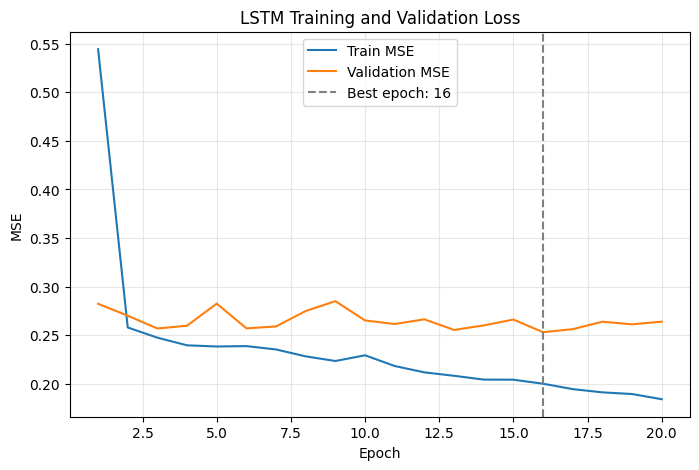

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), train_losses, label="Train MSE")
plt.plot(range(1, num_epochs + 1), val_losses, label="Validation MSE")
plt.axvline(best_epoch, linestyle="--", color="gray",
            label=f"Best epoch: {best_epoch}")

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


#### Test Set Evaluation

We evaluate the trained LSTM on the test set to measure its performance on unseen images.

The model's weights remain unchanged, and we use MSE to measure the prediction error.

In [7]:

model.eval()
total_test_loss = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        predictions = model(images)
        loss = criterion(predictions, labels)

        total_test_loss += loss.item() * images.size(0)

test_mse = total_test_loss / len(test_loader.dataset)

print(f"Test MSE: {test_mse:.4f}")


Test MSE: 0.2587


#### Prediction Examples

We visualize five images from the test set to compare the LSTM predictions with their actual MOS values.

This provides a concrete example of the model's predictions beyond the overall test MSE.

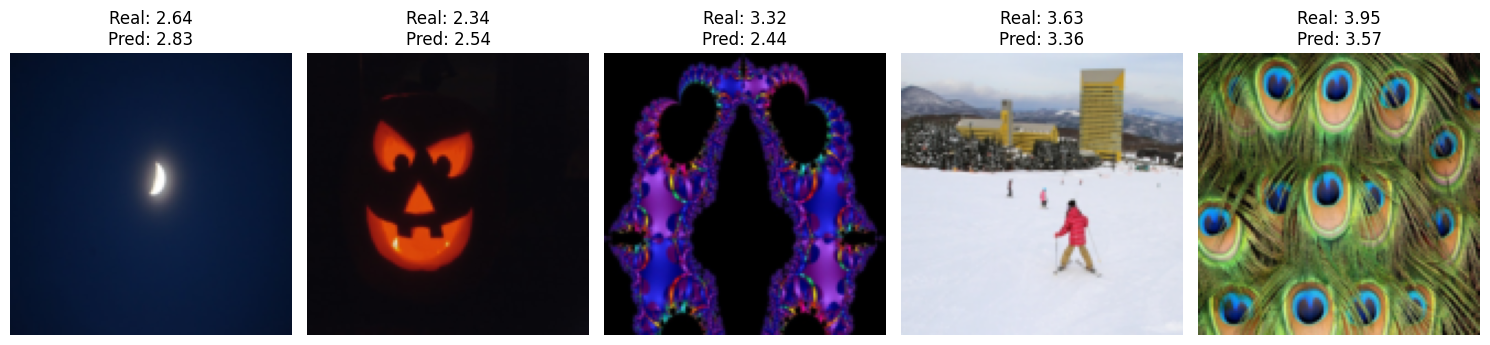

In [8]:

images, labels = next(iter(test_loader))
images, labels = images[:5], labels[:5]

model.eval()
with torch.no_grad():
    predictions = model(images.to(device)).cpu()

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i in range(5):
    image = images[i].permute(1, 2, 0) * 0.5 + 0.5

    axes[i].imshow(image.clamp(0, 1))
    axes[i].set_title(
        f"Real: {labels[i].item():.2f}\n"
        f"Pred: {predictions[i].item():.2f}"
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()


#### Results Analysis

The training MSE decreases from 0.5444 to 0.1840 over 20 epochs, showing that the LSTM progressively learns from the training data.

However, the validation MSE starts to plateau around epoch 3, while the training loss continues to decrease. This suggests potential overfitting, as the model improves on the training data without achieving comparable improvements on unseen validation data.

The best validation MSE (0.2531) is reached at epoch 16, so our checkpointing strategy selects this epoch. However, the validation MSE at epoch 3 was already 0.2569, meaning that 13 additional epochs only improved it by approximately 1.5%.

This highlights a limitation of our current approach: selecting the epoch with the lowest validation MSE does not necessarily lead to a meaningful improvement in generalization. Stopping around epoch 3 could have been a more conservative choice, potentially reducing overfitting while achieving similar validation performance.

The selected model achieves a Test MSE of 0.2587 (RMSE ≈ 0.51 MOS points) on 1,008 unseen images, close to its validation MSE. The prediction examples show that the LSTM estimates some MOS values reasonably well, but still makes larger errors on certain images. For example, an image rated 3.32 is predicted at 2.44.

Overall, the LSTM learns to estimate image quality, but the results reveal limitations in its generalization and training strategy. In Milestone 4, we will introduce early stopping to stop training when validation performance no longer improves meaningfully, instead of relying only on the lowest validation MSE.